# Caso 6. Brecha digital en Yucatán
**Análisis de Datos e Inteligencia de Negocios · Evaluación de la Unidad II**

**Fuente:** Censo de Población y Vivienda 2020, *Principales resultados por localidad (ITER)*, INEGI.
**Ámbito:** los 106 municipios de Yucatán, con variables de vivienda que comparten el mismo universo de referencia.

### Preguntas clave
1. ¿Cómo se distinguen los registros estatales, municipales y de localidad y qué implicaciones tiene mezclarlos en un cálculo?
2. ¿Qué municipios presentan los menores porcentajes de viviendas con internet?
3. ¿Qué municipios concentran el mayor número de viviendas sin internet?
4. ¿Coinciden los municipios con mayor proporción de viviendas sin acceso con aquellos que tienen más viviendas en esa condición?
5. ¿Qué diferencias existen entre el porcentaje de acceso de cada municipio y el porcentaje estatal?
6. ¿Cómo cambia la priorización de municipios si el criterio es la proporción sin acceso o el número de viviendas afectadas? ¿Qué límites tiene utilizar información de 2020 para una decisión actual?

### Estructura de la libreta
1. Data Collection: recolección de datos
2. Data Description: descripción de datos
3. Data Quality: calidad de datos
4. Manipulación: tabla municipal e indicadores
5. Data Exploration: exploración de datos
6. Respuestas a las preguntas clave
7. Indicadores, hallazgos, recomendación y limitaciones

In [1]:
from pathlib import Path
import urllib.request
import zipfile

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

## 1. Data Collection: recolección de datos

| Elemento | Detalle |
|---|---|
| Institución responsable | Instituto Nacional de Estadística y Geografía (INEGI) |
| Programa | Censo de Población y Vivienda 2020 (Información de Interés Nacional, SNIEG) |
| Producto | Principales resultados por localidad (ITER), entidad 31 Yucatán, formato CSV |
| Enlace de origen | https://www.inegi.org.mx/programas/ccpv/2020/#datos_abiertos |
| Archivo descargado | https://www.inegi.org.mx/contenidos/programas/ccpv/2020/datosabiertos/iter/iter_31_cpv2020_csv.zip |
| Fecha de consulta | 28 de octubre de 2026 |
| Versión o corte | Archivo actualizado por INEGI el 19 de mayo de 2022 (ver metadatos). Fecha de referencia del censo: 15 de marzo de 2020 |
| Cobertura | Yucatán: total estatal, 106 municipios y todas sus localidades |

**Justificación de la selección.** El ITER publica resultados censales de población y vivienda desagregados por municipio y localidad. El análisis utiliza el universo de viviendas particulares habitadas con características, definido por el diccionario oficial. Así podemos comparar los 106 municipios sin el error de muestreo de una encuesta. Esto no elimina posibles errores de cobertura o respuesta. La ENDUTIH no proporciona estimaciones representativas para cada uno de los 106 municipios. Usamos una sola fuente, por lo que no hace falta compatibilizar fuentes distintas.

La siguiente celda descarga y descomprime los datos si todavía no están en la carpeta `datos/`.

**Revisión de reproducibilidad:** 6 de noviembre de 2026. La fecha de consulta original se conserva. Los archivos originales y su diccionario se incluyen en la entrega.


In [2]:
URL = "https://www.inegi.org.mx/contenidos/programas/ccpv/2020/datosabiertos/iter/iter_31_cpv2020_csv.zip"
DATOS = Path("datos")
ZIP = DATOS / "iter_31_cpv2020_csv.zip"
BASE = DATOS / "iter_31_cpv2020"

DATOS.mkdir(exist_ok=True)
if not ZIP.exists():
    urllib.request.urlretrieve(URL, ZIP)
if not BASE.exists():
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(DATOS)

for archivo in sorted(BASE.rglob("*.*")):
    print(archivo, f"{archivo.stat().st_size / 1024:,.0f} KB")

datos\iter_31_cpv2020\catalogos\tam_loc.csv.csv 0 KB
datos\iter_31_cpv2020\conjunto_de_datos\conjunto_de_datos_iter_31CSV20.csv 1,972 KB
datos\iter_31_cpv2020\diccionario_datos\diccionario_datos_iter_31CSV20.csv 70 KB
datos\iter_31_cpv2020\metadatos\metadatos_iter_31_cpv2020.txt 2 KB


El paquete incluye el conjunto de datos, el **diccionario de datos**, un catálogo de tamaño de localidad y los **metadatos**. Los metadatos documentan la versión del archivo:

In [3]:
print((BASE / "metadatos" / "metadatos_iter_31_cpv2020.txt").read_text(encoding="utf-8-sig"))

identifier: MEX-INEGI.ESD2.01-CPV-2020

title: Principales resultados por localidad (ITER) del Censo de Población y Vivienda 2020. Datos oportunos

description: 
INEGI. Censo de Población y Vivienda 2020. SNIEG. Información de Interés Nacional.
Conjunto de indicadores de población y vivienda a nivel localidad de la entidad federativa de Yucatán, provenientes del Censo de Población y Vivienda 2020.

NOTA:
El 16 de marzo de 2021, se reemplazó el archivo del Conjunto de datos, debido a que se incorporó la variable Total de viviendas particulares habitadas con características. Asimismo, en el archivo Diccionario de datos se hizo una revisión para mejorar la redacción de la descripción de los indicadores.

El 16 de abril de 2021, se reemplazó el archivo del Diccionario de datos, debido a que se mejoró la redacción de algunos indicadores.

El 26 de julio de 2021, se reemplazó el archivo del Diccionario de datos, debido a que el nombre del mnemónico del indicador Población masculina de 3 años

## 2. Data Description: descripción de datos

Leemos todas las columnas como texto (`dtype=str`) para no perder los ceros a la izquierda de las claves (`001`, `0000`) y para detectar códigos especiales antes de convertir a números.

In [4]:
iter_yuc = pd.read_csv(
    BASE / "conjunto_de_datos" / "conjunto_de_datos_iter_31CSV20.csv",
    dtype=str,
    encoding="utf-8-sig"
)
print("Registros y columnas:", iter_yuc.shape)
iter_yuc.iloc[:6, :10]

Registros y columnas: (2691, 286)


,ENTIDAD,NOM_ENT,MUN,NOM_MUN,LOC,NOM_LOC,LONGITUD,LATITUD,ALTITUD,POBTOT
0,31,Yucatán,000,Total de la entidad Yucatán,0000,Total de la Entidad,NaN,NaN,NaN,2320898
1,31,Yucatán,000,Total de la entidad Yucatán,9998,Localidades de una vivienda,NaN,NaN,NaN,3950
2,31,Yucatán,000,Total de la entidad Yucatán,9999,Localidades de dos viviendas,NaN,NaN,NaN,955
3,31,Yucatán,001,Abalá,0000,Total del Municipio,NaN,NaN,NaN,6550
4,31,Yucatán,001,Abalá,0001,Abalá,"89°40'51.191"" W","20°38'51.280"" N",0012,2039
5,31,Yucatán,001,Abalá,0003,Mucuyché,"89°36'14.421"" W","20°37'25.187"" N",0014,490


In [5]:
diccionario = pd.read_csv(
    BASE / "diccionario_datos" / "diccionario_datos_iter_31CSV20.csv",
    encoding="utf-8-sig",
    header=None,
    skiprows=5
).iloc[:, :6]
diccionario.columns = ["Num", "Indicador", "Descripcion", "Mnemonico", "Rangos", "Longitud"]
diccionario = diccionario.dropna(subset=["Mnemonico"])
print("Indicadores documentados:", len(diccionario))

Indicadores documentados: 286


### ¿Qué representa cada registro?

Cada fila es un **ámbito geográfico** con sus totales de población y vivienda. Las claves que lo identifican son `ENTIDAD`, `MUN` y `LOC`. Su significado está en el diccionario oficial:

In [6]:
diccionario[diccionario["Mnemonico"].isin(["ENTIDAD", "MUN", "LOC", "TAMLOC"])][["Mnemonico", "Indicador", "Descripcion"]]

,Mnemonico,Indicador,Descripcion
0,ENTIDAD,Clave de entidad federativa,Código que identifica a la entidad federativa. El código 00 identifica a los registros con los totales a nivel nacional.
2,MUN,Clave de municipio o demarcación territorial,"Código que identifica al municipio o demarcación territorial al interior de una entidad federativa, conforme al Marco Geoestadístico. El código 000 identifica a los registros con los totales a niv..."
4,LOC,Clave de localidad,Código que identifica a la localidad al interior de cada municipio o demarcación territorial conforme al Marco Geoestadístico. El código 0000 identifica a los registros con los totales a nivel de ...
285,TAMLOC,Tamaño de localidad,"Total de personas que residen habitualmente en la localidad, y se clasifica el tamaño con base en el número de la población de la localidad."


In [7]:
def nivel(fila):
    if fila["MUN"] == "000" and fila["LOC"] == "0000":
        return "1 Estatal"
    if fila["MUN"] == "000":
        return "2 Estatal: agrupación de localidades pequeñas"
    if fila["LOC"] == "0000":
        return "3 Municipal"
    if fila["LOC"] in ("9998", "9999"):
        return "4 Municipal: agrupación de localidades pequeñas"
    return "5 Localidad"

iter_yuc["NIVEL"] = iter_yuc.apply(nivel, axis=1)

iter_yuc.groupby("NIVEL").agg(
    registros=("LOC", "size"),
    ejemplo_NOM_LOC=("NOM_LOC", "first")
)

,registros,ejemplo_NOM_LOC
NIVEL,,
1 Estatal,1,Total de la Entidad
2 Estatal: agrupación de localidades pequeñas,2,Localidades de una vivienda
3 Municipal,106,Total del Municipio
4 Municipal: agrupación de localidades pequeñas,148,Localidades de una vivienda
5 Localidad,2434,Abalá


Hay cinco tipos de registro en el mismo archivo:

- **1 registro estatal** (`MUN = 000`, `LOC = 0000`): "Total de la Entidad".
- **106 registros municipales** (`LOC = 0000`): "Total del Municipio".
- **2,434 registros de localidades individuales** (`LOC` de 0001 a 9997).
- **148 agrupaciones municipales**: `LOC = 9998` ("Localidades de una vivienda") y `LOC = 9999` ("Localidades de dos viviendas").
- **2 agrupaciones a nivel estatal** con esos mismos códigos 9998 y 9999.

### Variables seleccionadas

El caso pide trabajar con variables de vivienda con **universos de referencia compatibles**. Leemos sus definiciones en el diccionario:

In [8]:
VARIABLES = ["POBTOT", "TVIVPARHAB", "VIVPAR_HAB", "VIVPARH_CV",
             "VPH_INTER", "VPH_PC", "VPH_CEL", "VPH_SINCINT", "VPH_SINTIC"]

diccionario[diccionario["Mnemonico"].isin(VARIABLES)][["Mnemonico", "Indicador", "Descripcion"]]

,Mnemonico,Indicador,Descripcion
9,POBTOT,Población total,"Total de personas que residen habitualmente en el país, la entidad federativa, el municipio o la demarcación territorial y la localidad. Incluye la estimación del número de personas en viviendas p..."
235,VIVPAR_HAB,Viviendas particulares habitadas,Viviendas particulares habitadas de cualquier clase: casa única en el terreno; casa que comparte terreno con otra(s); casa dúplex; departamento en edificio; vivienda en vecindad o cuartería; vivie...
236,VIVPARH_CV,Total de viviendas particulares habitadas con características,"Viviendas particulares habitadas a las que se les captan sus características, incluye casa única en el terreno; casa que comparte terreno con otra(s); casa dúplex; departamento en edificio; vivien..."
237,TVIVPARHAB,Total de viviendas particulares habitadas,Viviendas particulares habitadas de cualquier clase: casa única en el terreno; casa que comparte terreno con otra(s); casa dúplex; departamento en edificio; vivienda en vecindad o cuartería; vivie...
274,VPH_PC,"Viviendas particulares habitadas que disponen de computadora, laptop o tablet","Viviendas particulares habitadas que tienen computadora, laptop o tablet. Comprende las viviendas particulares para las que se captaron las características de la vivienda, clasificadas como: casa ..."
276,VPH_CEL,Viviendas particulares habitadas que disponen de teléfono celular,"Viviendas particulares habitadas que tienen teléfono celular. Comprende las viviendas particulares para las que se captaron las características de la vivienda, clasificadas como: casa única en el ..."
277,VPH_INTER,Viviendas particulares habitadas que disponen de Internet,"Viviendas particulares habitadas que tienen Internet. Comprende las viviendas particulares para las que se captaron las características de la vivienda, clasificadas como: casa única en el terreno;..."
283,VPH_SINCINT,Viviendas particulares habitadas sin computadora ni Internet,"Viviendas particulares habitadas que no cuentan con computadora, laptop o tablet ni Internet. Comprende las viviendas particulares para las que se captaron las características de la vivienda, clas..."
284,VPH_SINTIC,Viviendas particulares habitadas sin tecnologías de la información y de la comunicación (TIC),"Viviendas particulares habitadas que no cuentan con algún aparato o dispositivo para oír radio; televisor; computadora, laptop o tablet; línea telefónica fija; teléfono celular; Internet; servicio..."


| Variable | Significado | Tipo | Unidad | Papel en el análisis |
|---|---|---|---|---|
| `ENTIDAD`, `MUN`, `LOC` | Claves geográficas | Texto (código) | — | Identificar el nivel del registro |
| `NOM_MUN`, `NOM_LOC` | Nombres | Texto | — | Etiquetas |
| `TAMLOC` | Tamaño de localidad (catálogo 1–14) | Categórica ordinal | — | Descripción |
| `POBTOT` | Población total | Entera | Personas | Contexto y ruralidad |
| `VIVPARH_CV` | Viviendas particulares habitadas **con características** | Entera | Viviendas | **Denominador** |
| `TVIVPARHAB` | Total de viviendas particulares habitadas | Entera | Viviendas | Comparación de denominadores |
| `VPH_INTER` | Viviendas particulares habitadas que disponen de Internet | Entera | Viviendas | **Numerador** |
| `VPH_PC` | … que disponen de computadora, laptop o tablet | Entera | Viviendas | Contexto TIC |
| `VPH_CEL` | … que disponen de teléfono celular | Entera | Viviendas | Contexto TIC |
| `VPH_SINCINT` | … sin computadora ni Internet | Entera | Viviendas | Contexto TIC |
| `VPH_SINTIC` | … sin ninguna TIC | Entera | Viviendas | Contexto TIC |

**¿Por qué `VIVPARH_CV` como denominador?** Las variables `VPH_*` se captan solo para las viviendas particulares *para las que se captaron las características de la vivienda*. Ese universo excluye los locales no construidos para habitación, las viviendas móviles y los refugios. `VIVPARH_CV` es exactamente ese universo. INEGI la añadió al archivo en marzo de 2021 (ver metadatos) para que los porcentajes se calculen con un denominador compatible. Usar `TVIVPARHAB` mezclaría universos distintos y subestimaría ligeramente el acceso.

**Alcance de la información:**
- Mide la **disponibilidad de Internet en la vivienda**. No mide el uso individual, la velocidad, la calidad ni el acceso fuera de casa (escuela, trabajo, datos móviles personales).
- Es un **conteo censal** con fecha de referencia de marzo de 2020: una fotografía de marzo de 2020 de COVID-19.
- `VPH_INTER` cuenta las viviendas que **sí** disponen de Internet. Su complemento ("sin Internet") incluye también a las viviendas que no especificaron. ITER no publica el "no especificado" por separado, así que el conteo sin acceso es un **límite superior**.

**Precisión de interpretación:** disponibilidad de Internet en la vivienda no equivale necesariamente a un contrato fijo de banda ancha. El ITER tampoco identifica motivos de falta de acceso. En esta libreta, «sin Internet» nombra el complemento de las viviendas que sí reportan disponibilidad, con la limitación indicada sobre no especificados.


## 3. Data Quality: calidad de datos

Evaluamos cuatro dimensiones: **completitud, unicidad, validez y consistencia**.

### 3.1 Completitud: valores nulos y códigos especiales

In [9]:
vista = iter_yuc[["NIVEL"] + VARIABLES]

print("Valores nulos en las variables seleccionadas:", vista[VARIABLES].isna().sum().sum())

no_numericos = vista[VARIABLES].apply(lambda col: ~col.str.fullmatch(r"\d+"))
print("Valores no numéricos encontrados:", pd.unique(vista[VARIABLES].where(no_numericos).stack()))

no_numericos.groupby(vista["NIVEL"]).sum()

Valores nulos en las variables seleccionadas: 0
Valores no numéricos encontrados: <ArrowStringArray>
[nan, '*']
Length: 2, dtype: str


,POBTOT,TVIVPARHAB,VIVPAR_HAB,VIVPARH_CV,VPH_INTER,VPH_PC,VPH_CEL,VPH_SINCINT,VPH_SINTIC
NIVEL,,,,,,,,,
1 Estatal,0,0,0,0,0,0,0,0,0
2 Estatal: agrupación de localidades pequeñas,0,0,0,0,0,0,0,0,0
3 Municipal,0,0,0,0,0,0,0,0,0
4 Municipal: agrupación de localidades pequeñas,0,45,45,45,45,45,45,45,45
5 Localidad,0,1604,1604,1604,1604,1604,1604,1604,1604


No hay nulos, pero sí un **código especial**: el asterisco `*`. Antes de modificarlo hay que interpretarlo. INEGI aplica el **principio de confidencialidad** de la Ley del SNIEG: en las localidades con una o dos viviendas, las características se reservan para no identificar a sus habitantes. Por eso esos datos aparecen agrupados en los registros 9998 y 9999.

Comprobemos que los asteriscos se concentran en localidades diminutas:

In [10]:
localidades = iter_yuc[iter_yuc["NIVEL"] == "5 Localidad"].copy()
localidades["POBTOT"] = localidades["POBTOT"].astype(int)
con_asterisco = localidades["VPH_INTER"] == "*"

print(f"Localidades con '*' en VPH_INTER: {con_asterisco.sum():,} de {len(localidades):,} ({con_asterisco.mean():.1%})")
print(f"Población que vive en ellas: {localidades.loc[con_asterisco, 'POBTOT'].sum():,} personas "
      f"({localidades.loc[con_asterisco, 'POBTOT'].sum() / localidades['POBTOT'].sum():.2%} del total)")
localidades.loc[con_asterisco, "POBTOT"].describe()

Localidades con '*' en VPH_INTER: 1,604 de 2,434 (65.9%)
Población que vive en ellas: 4,905 personas (0.21% del total)


count    1604.000000
mean        3.057980
std         2.373382
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max        18.000000
Name: POBTOT, dtype: float64

Casi dos tercios de las localidades tienen el dato reservado, pero en ellas vive **menos del 0.3 %** de la población. Lo más importante para nuestro caso: **los 106 registros municipales no tienen ningún asterisco** (tabla 3.1). INEGI incluye la información reservada dentro de los totales municipales.

**Tratamiento:** no imputamos ni sustituimos los `*` por cero. Trabajamos con el nivel municipal, que está completo. Reemplazarlos por cero subestimaría el acceso y el número de viviendas.

### 3.2 Unicidad

In [11]:
clave = ["ENTIDAD", "MUN", "LOC"]
print("Registros duplicados por clave ENTIDAD-MUN-LOC:", iter_yuc.duplicated(subset=clave).sum())
print("Filas completamente duplicadas:", iter_yuc.duplicated().sum())

municipal = iter_yuc[iter_yuc["NIVEL"] == "3 Municipal"]
print("Municipios:", len(municipal), "| claves únicas:", municipal["MUN"].nunique(), "| nombres únicos:", municipal["NOM_MUN"].nunique())

Registros duplicados por clave ENTIDAD-MUN-LOC: 0


Filas completamente duplicadas: 0
Municipios: 106 | claves únicas: 106 | nombres únicos: 106


La combinación de claves identifica de forma única cada registro, y hay exactamente un registro por cada uno de los **106 municipios** de Yucatán.

### 3.3 Consistencia: ¿cuadran los niveles entre sí?

In [12]:
municipios = municipal[["MUN", "NOM_MUN"] + VARIABLES].copy()
municipios[VARIABLES] = municipios[VARIABLES].astype(int)

estatal = iter_yuc[iter_yuc["NIVEL"] == "1 Estatal"][VARIABLES].astype(int).iloc[0]

pd.DataFrame({
    "Total estatal": estatal,
    "Suma de municipios": municipios[VARIABLES].sum(),
}).assign(Diferencia=lambda t: t["Suma de municipios"] - t["Total estatal"])

,Total estatal,Suma de municipios,Diferencia
POBTOT,2320898,2320898,0
TVIVPARHAB,658085,658085,0
VIVPAR_HAB,633198,633198,0
VIVPARH_CV,656907,656907,0
VPH_INTER,339142,339142,0
VPH_PC,246448,246448,0
VPH_CEL,580440,580440,0
VPH_SINCINT,283586,283586,0
VPH_SINTIC,16519,16519,0


In [13]:
pob = iter_yuc[["MUN", "LOC", "NIVEL"]].assign(POBTOT=iter_yuc["POBTOT"].astype(int))
total_mun = pob[pob["NIVEL"] == "3 Municipal"].set_index("MUN")["POBTOT"]

solo_individuales = pob[pob["NIVEL"] == "5 Localidad"].groupby("MUN")["POBTOT"].sum()
individuales_y_grupos = pob[pob["NIVEL"].isin(["4 Municipal: agrupación de localidades pequeñas", "5 Localidad"])].groupby("MUN")["POBTOT"].sum()

print("Municipios donde la suma de localidades individuales = total municipal:",
      (solo_individuales.reindex(total_mun.index) == total_mun).sum(), "de 106")
print("Municipios donde individuales + agrupaciones 9998/9999 = total municipal:",
      (individuales_y_grupos.reindex(total_mun.index) == total_mun).sum(), "de 106")
print(f"\nSuma de POBTOT de TODOS los registros: {pob['POBTOT'].sum():,}")
print(f"Población real de Yucatán:            {estatal['POBTOT']:,}")
print(f"Factor de sobreconteo: {pob['POBTOT'].sum() / estatal['POBTOT']:.2f}×")

Municipios donde la suma de localidades individuales = total municipal:

 106 de 106
Municipios donde individuales + agrupaciones 9998/9999 = total municipal: 6 de 106

Suma de POBTOT de TODOS los registros: 6,972,504
Población real de Yucatán:            2,320,898
Factor de sobreconteo: 3.00×


Resultados de consistencia:

- La suma de los 106 municipios reproduce **exactamente** el total estatal en todas las variables.
- La población de las localidades individuales suma exactamente el total de cada municipio. Las agrupaciones 9998/9999 **vuelven a contar** a esas localidades pequeñas: son un resumen alternativo, no filas adicionales.
- Sumar todas las filas del archivo cuenta a cada persona unas **3 veces** (estado + municipio + localidad). Es la principal trampa de esta fuente (pregunta 1).

### 3.4 Validez: rangos y reglas lógicas

In [14]:
reglas = {
    "Valores negativos": (municipios[VARIABLES] < 0).any(axis=1),
    "VPH_INTER > VIVPARH_CV": municipios["VPH_INTER"] > municipios["VIVPARH_CV"],
    "VPH_PC > VIVPARH_CV": municipios["VPH_PC"] > municipios["VIVPARH_CV"],
    "VPH_SINCINT > VIVPARH_CV": municipios["VPH_SINCINT"] > municipios["VIVPARH_CV"],
    "VIVPARH_CV > TVIVPARHAB": municipios["VIVPARH_CV"] > municipios["TVIVPARHAB"],
    "VIVPARH_CV = 0": municipios["VIVPARH_CV"] == 0,
}
pd.Series({regla: int(falla.sum()) for regla, falla in reglas.items()}, name="municipios que incumplen")

Valores negativos           0
VPH_INTER > VIVPARH_CV      0
VPH_PC > VIVPARH_CV         0
VPH_SINCINT > VIVPARH_CV    0
VIVPARH_CV > TVIVPARHAB     0
VIVPARH_CV = 0              0
Name: municipios que incumplen, dtype: int64

Ningún municipio viola las reglas lógicas: el numerador nunca supera al denominador y ningún denominador es cero, así que todos los porcentajes estarán entre 0 y 100 %.

### 3.5 Efecto del denominador

Cuantificamos qué pasaría si usáramos un universo incompatible:

In [15]:
for den in ["VIVPARH_CV", "TVIVPARHAB", "VIVPAR_HAB"]:
    print(f"% estatal de viviendas con Internet usando {den:<11}: {estatal['VPH_INTER'] / estatal[den] * 100:.2f} %")

% estatal de viviendas con Internet usando VIVPARH_CV : 51.63 %
% estatal de viviendas con Internet usando TVIVPARHAB : 51.53 %
% estatal de viviendas con Internet usando VIVPAR_HAB : 53.56 %


La diferencia entre `VIVPARH_CV` y `TVIVPARHAB` es pequeña a nivel estatal (≈0.1 pp). Aun así, la decisión metodológica correcta es el universo compatible. `VIVPAR_HAB` excluye a las viviendas sin información de ocupantes, que sí están incluidas en `VPH_INTER`, y daría el porcentaje más sesgado de los tres.

### 3.6 Valores extremos

In [16]:
municipios["pct_internet"] = municipios["VPH_INTER"] / municipios["VIVPARH_CV"] * 100

q1, q3 = municipios["pct_internet"].quantile([0.25, 0.75])
iqr = q3 - q1
limites = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
print(f"Límites de Tukey para % con Internet: {limites[0]:.1f} % a {limites[1]:.1f} %")

extremos = municipios[(municipios["pct_internet"] < limites[0]) | (municipios["pct_internet"] > limites[1])]
extremos[["NOM_MUN", "VIVPARH_CV", "VPH_INTER", "VPH_PC", "VPH_CEL", "pct_internet"]].round(2)

Límites de Tukey para % con Internet: -0.9 % a 57.0 %


,NOM_MUN,VIVPARH_CV,VPH_INTER,VPH_PC,VPH_CEL,pct_internet
209,Conkal,4975,2957,2531,4699,59.44
826,Mérida,303526,217177,170788,288499,71.55
1279,Progreso,18449,11557,6308,17193,62.64
1306,Río Lagartos,1100,633,196,998,57.55
1364,San Felipe,631,411,123,596,65.13


In [17]:
iter_yuc.loc[iter_yuc["MUN"] == "022", ["NOM_LOC", "POBTOT", "VIVPARH_CV", "VPH_INTER", "VPH_PC", "VPH_CEL"]]

,NOM_LOC,POBTOT,VIVPARH_CV,VPH_INTER,VPH_PC,VPH_CEL
422,Total del Municipio,4363,1010,10,38,670
423,Chikindzonot,3019,678,4,20,521
424,Chan-Chichimilá,419,97,1,5,68
425,Ichmul,860,217,5,13,72
426,Chan Santa María,24,8,0,0,5
427,Chucteil,17,4,0,0,1
428,Chan Kankabdzonot,2,*,*,*,*
429,El Arca de Noé,1,*,*,*,*
430,San Isidro,17,3,0,0,3
431,Wilberth Kauil Alcocer,4,*,*,*,*


**Interpretación de los extremos antes de modificar:**

- El criterio de Tukey solo marca valores **altos**: Mérida (71.6 %), San Felipe, Progreso, Conkal y Río Lagartos. Son valores *legítimos*: la capital, un municipio conurbado (Conkal) y municipios costeros con actividad turística y pesquera. No se eliminan. Mérida se analiza también por separado porque concentra casi la mitad de las viviendas del estado.
- **Chikindzonot (0.99 %)** no sale como atípico según Tukey, pero es el mínimo y llama la atención: solo 10 de 1,010 viviendas reportan Internet. El dato es coherente: todas sus localidades muestran el mismo patrón, el 66 % de las viviendas sí tiene celular y solo el 3.8 % computadora. El ITER no permite atribuir este resultado a falta de infraestructura, precio o preferencias de contratación. Además, según el umbral de 2,500 habitantes, solo el 30.8 % de su población reside en localidades rurales. Lo conservamos y lo señalamos como caso que merecería verificación en campo.

**Ningún registro se elimina.** Los problemas detectados (asteriscos, agrupaciones duplicadas, mezcla de niveles) se resuelven filtrando el nivel municipal, que está completo y es consistente.

## 4. Manipulación: tabla municipal e indicadores

**Filtro:** `NIVEL == "3 Municipal"` (`MUN ≠ 000` y `LOC = 0000`). Así obtenemos una fila por municipio, sin doble conteo y sin datos reservados.

**Variables derivadas** (todas con denominador `VIVPARH_CV`):

| Indicador | Fórmula | Unidad |
|---|---|---|
| % de viviendas con Internet | `VPH_INTER / VIVPARH_CV × 100` | % |
| % de viviendas sin Internet | `100 − % con Internet` | % |
| Viviendas sin Internet | `VIVPARH_CV − VPH_INTER` | viviendas |
| Brecha respecto al estado | `% con Internet municipal − % con Internet estatal` | puntos porcentuales (pp) |
| Participación en el déficit estatal | `Viviendas sin Internet del municipio / Viviendas sin Internet del estado × 100` | % |
| % con computadora / con celular | `VPH_PC / VIVPARH_CV × 100`, `VPH_CEL / VIVPARH_CV × 100` | % |

El porcentaje estatal se calcula con los **totales** del estado. No es el promedio de los 106 porcentajes municipales, que daría el mismo peso a un municipio de 600 viviendas que a Mérida.

In [18]:
pct_estatal = estatal["VPH_INTER"] / estatal["VIVPARH_CV"] * 100
sin_estatal = estatal["VIVPARH_CV"] - estatal["VPH_INTER"]

municipios["pct_sin_internet"] = 100 - municipios["pct_internet"]
municipios["viv_sin_internet"] = municipios["VIVPARH_CV"] - municipios["VPH_INTER"]
municipios["brecha_pp"] = municipios["pct_internet"] - pct_estatal
municipios["part_deficit_pct"] = municipios["viv_sin_internet"] / sin_estatal * 100
municipios["pct_pc"] = municipios["VPH_PC"] / municipios["VIVPARH_CV"] * 100
municipios["pct_celular"] = municipios["VPH_CEL"] / municipios["VIVPARH_CV"] * 100

print(f"Viviendas particulares habitadas con características: {estatal['VIVPARH_CV']:,}")
print(f"Viviendas con Internet: {estatal['VPH_INTER']:,}")
print(f"Viviendas sin Internet: {sin_estatal:,}")
print(f"% estatal con Internet: {pct_estatal:.2f} %")
print(f"Promedio simple de los 106 municipios (NO es el dato estatal): {municipios['pct_internet'].mean():.2f} %")

Viviendas particulares habitadas con características: 656,907
Viviendas con Internet: 339,142
Viviendas sin Internet: 317,765
% estatal con Internet: 51.63 %
Promedio simple de los 106 municipios (NO es el dato estatal): 28.75 %


Hay una diferencia de más de 20 pp entre el porcentaje estatal (51.6 %) y el promedio simple de municipios (28.7 %). La mayoría de los municipios tiene niveles bajos de acceso, pero Mérida, con niveles altos, pesa mucho en el total estatal.

### Ruralidad (variable de contexto)

Para explorar qué se asocia con la brecha, calculamos el porcentaje de población de cada municipio que vive en localidades de menos de 2,500 habitantes, el umbral que INEGI usa para definir lo rural. Usamos `POBTOT`, que no tiene asteriscos, y solo las localidades individuales para no contar dos veces a las agrupaciones 9998/9999.

In [19]:
rural = (
    localidades.assign(pob_rural=localidades["POBTOT"].where(localidades["POBTOT"] < 2500, 0))
    .groupby("MUN")["pob_rural"].sum()
)
municipios["pct_pob_rural"] = municipios["MUN"].map(rural) / municipios["POBTOT"] * 100

tabla = municipios[["MUN", "NOM_MUN", "POBTOT", "VIVPARH_CV", "VPH_INTER", "viv_sin_internet",
                    "pct_internet", "pct_sin_internet", "brecha_pp", "part_deficit_pct",
                    "pct_pc", "pct_celular", "pct_pob_rural"]].reset_index(drop=True)
tabla.sort_values("pct_internet").head().round(2)

,MUN,NOM_MUN,POBTOT,VIVPARH_CV,VPH_INTER,viv_sin_internet,pct_internet,pct_sin_internet,brecha_pp,part_deficit_pct,pct_pc,pct_celular,pct_pob_rural
21,022,Chikindzonot,4363,1010,10,1000,0.99,99.01,-50.64,0.31,3.76,66.34,30.80
103,104,Yaxcabá,16350,4184,211,3973,5.04,94.96,-46.58,1.25,5.35,57.31,63.80
42,043,Kaua,3405,845,47,798,5.56,94.44,-46.06,0.25,10.06,76.92,15.45
16,017,Chankom,4686,1232,81,1151,6.57,93.43,-45.05,0.36,6.09,50.32,100.00
70,071,Sudzal,1949,577,44,533,7.63,92.37,-44.00,0.17,7.63,73.66,100.00


In [20]:
Path("datos/procesados").mkdir(parents=True, exist_ok=True)
tabla.round(4).to_csv("datos/procesados/brecha_digital_municipios_yucatan_2020.csv", index=False, encoding="utf-8-sig")
print("Guardado: datos/procesados/brecha_digital_municipios_yucatan_2020.csv")

Guardado: datos/procesados/brecha_digital_municipios_yucatan_2020.csv


## 5. Data Exploration: exploración de datos

### 5.1 Distribución del acceso a Internet entre municipios

In [21]:
tabla[["pct_internet", "viv_sin_internet", "VIVPARH_CV"]].describe().round(1)

,pct_internet,viv_sin_internet,VIVPARH_CV
count,106.0,106.0,106.0
mean,28.7,2997.8,6197.2
std,13.6,8744.6,29663.8
min,1.0,190.0,304.0
25%,20.8,699.2,990.0
50%,28.4,1137.0,1498.0
75%,35.3,2102.8,3093.8
max,71.6,86349.0,303526.0


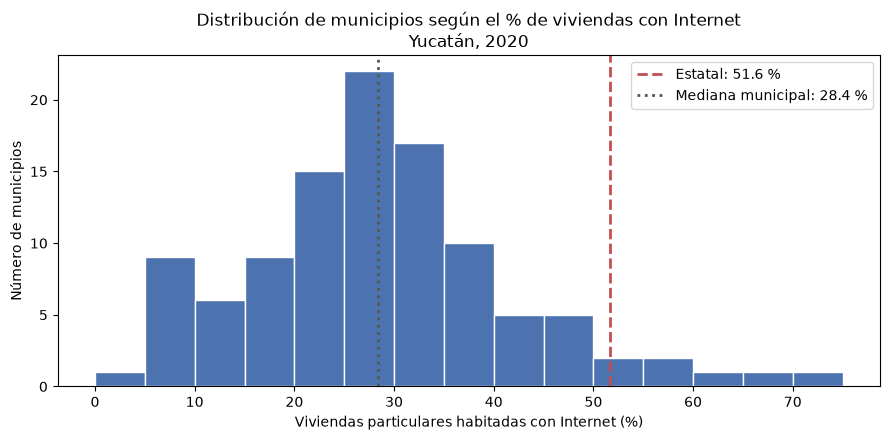

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(tabla["pct_internet"], bins=range(0, 80, 5), color="#4C72B0", edgecolor="white")
ax.axvline(pct_estatal, color="#C44E52", linestyle="--", linewidth=2, label=f"Estatal: {pct_estatal:.1f} %")
ax.axvline(tabla["pct_internet"].median(), color="#555555", linestyle=":", linewidth=2,
           label=f"Mediana municipal: {tabla['pct_internet'].median():.1f} %")
ax.set_title("Distribución de municipios según el % de viviendas con Internet\nYucatán, 2020")
ax.set_xlabel("Viviendas particulares habitadas con Internet (%)")
ax.set_ylabel("Número de municipios")
ax.legend()
plt.tight_layout()
plt.show()

In [23]:
print("Municipios por encima del porcentaje estatal:", (tabla["pct_internet"] > pct_estatal).sum())
print("Municipios con menos del 25 % de viviendas con Internet:", (tabla["pct_internet"] < 25).sum())
print(tabla.loc[tabla["pct_internet"] > pct_estatal, ["NOM_MUN", "pct_internet"]].round(1).to_string(index=False))

Municipios por encima del porcentaje estatal: 7
Municipios con menos del 25 % de viviendas con Internet: 40
     NOM_MUN  pct_internet
      Conkal          59.4
      Mérida          71.6
      Panabá          55.0
    Progreso          62.6
Río Lagartos          57.5
  San Felipe          65.1
 Santa Elena          53.1


La distribución está concentrada entre 15 y 40 % y tiene una cola a la derecha formada por muy pocos municipios. Solo **7 de 106** superan el porcentaje estatal: Mérida, San Felipe, Progreso, Conkal, Río Lagartos, Panabá y Santa Elena. La mitad de los municipios no llega al 28.4 % de viviendas conectadas, y 40 municipios están por debajo del 25 %.

### 5.2 Mérida frente al resto de Yucatán

In [24]:
grupo = tabla.assign(grupo=lambda t: t["NOM_MUN"].where(t["NOM_MUN"] == "Mérida", "Resto de Yucatán (105 municipios)"))
merida_resto = grupo.groupby("grupo")[["VIVPARH_CV", "VPH_INTER", "viv_sin_internet"]].sum()
merida_resto["pct_internet"] = merida_resto["VPH_INTER"] / merida_resto["VIVPARH_CV"] * 100
merida_resto["pct_viviendas_estado"] = merida_resto["VIVPARH_CV"] / estatal["VIVPARH_CV"] * 100
merida_resto["pct_deficit_estatal"] = merida_resto["viv_sin_internet"] / sin_estatal * 100
merida_resto.round(1)

,VIVPARH_CV,VPH_INTER,viv_sin_internet,pct_internet,pct_viviendas_estado,pct_deficit_estatal
grupo,,,,,,
Mérida,303526,217177,86349,71.6,46.2,27.2
Resto de Yucatán (105 municipios),353381,121965,231416,34.5,53.8,72.8


Mérida tiene el 46 % de las viviendas del estado y el 72 % de ellas tiene Internet. El resto de Yucatán, con el 54 % de las viviendas, llega al 34.5 %. Sin embargo, Mérida concentra **más de una cuarta parte** del déficit estatal (≈86 mil viviendas sin Internet).

### 5.3 Relación con la ruralidad y con otras TIC

In [25]:
correlaciones = tabla[["pct_internet", "pct_pob_rural", "pct_pc", "pct_celular"]].corr(method="spearman")["pct_internet"].drop("pct_internet")
correlaciones.round(2).rename("Correlación de Spearman con % con Internet")

pct_pob_rural   -0.13
pct_pc           0.63
pct_celular      0.59
Name: Correlación de Spearman con % con Internet, dtype: float64

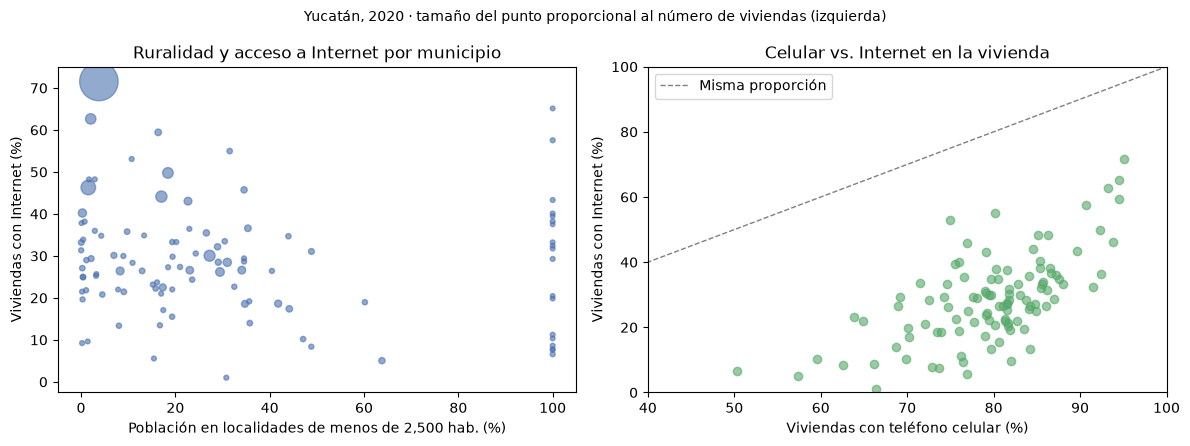

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(tabla["pct_pob_rural"], tabla["pct_internet"], s=tabla["VIVPARH_CV"] / 400 + 10, alpha=0.6, color="#4C72B0")
axes[0].set_title("Ruralidad y acceso a Internet por municipio")
axes[0].set_xlabel("Población en localidades de menos de 2,500 hab. (%)")
axes[0].set_ylabel("Viviendas con Internet (%)")

axes[1].scatter(tabla["pct_celular"], tabla["pct_internet"], alpha=0.6, color="#55A868")
axes[1].plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, label="Misma proporción")
axes[1].set_xlim(40, 100)
axes[1].set_ylim(0, 100)
axes[1].set_title("Celular vs. Internet en la vivienda")
axes[1].set_xlabel("Viviendas con teléfono celular (%)")
axes[1].set_ylabel("Viviendas con Internet (%)")
axes[1].legend()

fig.suptitle("Yucatán, 2020 · tamaño del punto proporcional al número de viviendas (izquierda)", fontsize=10)
plt.tight_layout()
plt.show()

- La asociación entre ruralidad y acceso es **negativa pero débil** (ρ ≈ −0.13). Muchos municipios con muy poco acceso tienen su población concentrada en una cabecera de más de 2,500 habitantes (Mayapán: 0.2 % de población rural y 9.2 % de viviendas con Internet). El tamaño de localidad, por sí solo, no explica la brecha.
- El acceso a Internet se asocia moderadamente con la disponibilidad de computadora (ρ ≈ 0.63) y de celular (ρ ≈ 0.59). Son asociaciones descriptivas que no prueban causalidad.
- Todos los puntos están **por debajo de la diagonal**: en todos los municipios hay más viviendas con celular que con Internet. El celular está muy extendido, pero no garantiza conexión a Internet en la vivienda, que es lo que mide el censo.

## 6. Respuestas a las preguntas clave

### Pregunta 1. ¿Cómo se distinguen los registros estatales, municipales y de localidad y qué implica mezclarlos?

Se distinguen por las claves `MUN` y `LOC` (sección 2):

| Nivel | Condición | Registros |
|---|---|---|
| Estatal | `MUN = 000` y `LOC = 0000` | 1 |
| Municipal | `MUN ≠ 000` y `LOC = 0000` | 106 |
| Localidad | `LOC` entre 0001 y 9997 | 2,434 |
| Agrupaciones de localidades de 1 y 2 viviendas | `LOC = 9998` o `9999` (2 estatales y 148 municipales) | 150 |

**Implicaciones de mezclarlos** (demostradas en la sección 3.3):

In [27]:
viv = iter_yuc[["NIVEL", "VIVPARH_CV", "VPH_INTER"]].copy()
viv = viv[(viv["VIVPARH_CV"] != "*") & (viv["VPH_INTER"] != "*")]
viv[["VIVPARH_CV", "VPH_INTER"]] = viv[["VIVPARH_CV", "VPH_INTER"]].astype(int)

mezcla = pd.DataFrame({
    "Cálculo": ["Correcto: solo registro estatal",
                "Correcto: suma de municipios",
                "Incorrecto: suma de todo el archivo (sin '*')"],
    "Viviendas con Internet": [estatal["VPH_INTER"], municipios["VPH_INTER"].sum(), viv["VPH_INTER"].sum()],
})
mezcla["Veces el valor real"] = (mezcla["Viviendas con Internet"] / estatal["VPH_INTER"]).round(2)
mezcla

,Cálculo,Viviendas con Internet,Veces el valor real
0,Correcto: solo registro estatal,339142,1.0
1,Correcto: suma de municipios,339142,1.0
2,Incorrecto: suma de todo el archivo (sin '*'),1017791,3.0


- **Sumar todo el archivo** triplica los conteos, porque cada vivienda aparece en el total estatal, en su municipio y en su localidad (y algunas también en las agrupaciones 9998/9999).
- Un **promedio** de porcentajes sobre todo el archivo mezclaría el estado, municipios y localidades de 3 viviendas con el mismo peso.
- Trabajar con localidades obliga a lidiar con **1,649 valores reservados** (`*`). El nivel municipal no tiene ninguno.

**Decisión:** el análisis usa exclusivamente los 106 registros municipales y el registro estatal como referencia.

### Pregunta 2. ¿Qué municipios presentan los menores porcentajes de viviendas con Internet?

In [28]:
menor_acceso = tabla.nsmallest(10, "pct_internet")[["NOM_MUN", "VIVPARH_CV", "VPH_INTER", "pct_internet", "brecha_pp"]]
menor_acceso.round(2)

,NOM_MUN,VIVPARH_CV,VPH_INTER,pct_internet,brecha_pp
21,Chikindzonot,1010,10,0.99,-50.64
103,Yaxcabá,4184,211,5.04,-46.58
42,Kaua,845,47,5.56,-46.06
16,Chankom,1232,81,6.57,-45.05
70,Sudzal,577,44,7.63,-44.00
85,Tepakán,682,53,7.77,-43.86
93,Tixmehuac,1421,119,8.37,-43.25
9,Cantamayec,743,64,8.61,-43.01
48,Mayapán,943,87,9.23,-42.40
76,Tekal de Venegas,769,74,9.62,-42.00


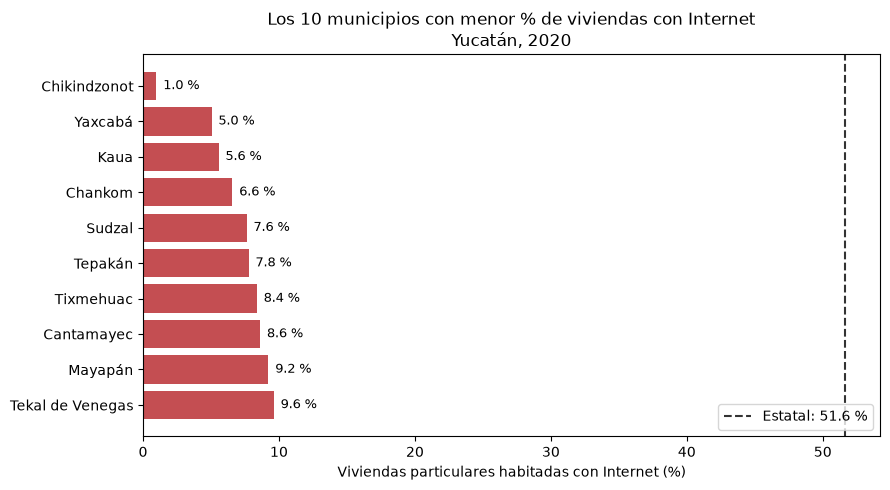

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
datos = menor_acceso.sort_values("pct_internet", ascending=False)
ax.barh(datos["NOM_MUN"], datos["pct_internet"], color="#C44E52")
ax.axvline(pct_estatal, color="#333333", linestyle="--", label=f"Estatal: {pct_estatal:.1f} %")
for y, v in enumerate(datos["pct_internet"]):
    ax.text(v + 0.5, y, f"{v:.1f} %", va="center", fontsize=9)
ax.set_title("Los 10 municipios con menor % de viviendas con Internet\nYucatán, 2020")
ax.set_xlabel("Viviendas particulares habitadas con Internet (%)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Respuesta:** los porcentajes más bajos están en **Chikindzonot (1.0 %)**, **Yaxcabá (5.0 %)**, **Kaua (5.6 %)**, **Chankom (6.6 %)** y **Sudzal (7.6 %)**. Los diez municipios de la lista tienen menos del 10 % de sus viviendas conectadas, es decir, al menos 42 pp por debajo del estado. Son municipios pequeños y rurales, principalmente del oriente y el sur del estado.

### Pregunta 3. ¿Qué municipios concentran el mayor número de viviendas sin Internet?

In [30]:
mas_viviendas = tabla.nlargest(10, "viv_sin_internet")[["NOM_MUN", "VIVPARH_CV", "viv_sin_internet", "pct_sin_internet", "part_deficit_pct"]]
mas_viviendas["part_acumulada_pct"] = mas_viviendas["part_deficit_pct"].cumsum()
mas_viviendas.round(2)

,NOM_MUN,VIVPARH_CV,viv_sin_internet,pct_sin_internet,part_deficit_pct,part_acumulada_pct
49,Mérida,303526,86349,28.45,27.17,27.17
40,Kanasín,39988,21480,53.72,6.76,33.93
95,Tizimín,21212,14839,69.96,4.67,38.60
101,Valladolid,22006,12295,55.87,3.87,42.47
100,Umán,19347,9718,50.23,3.06,45.53
78,Tekax,11529,8511,73.82,2.68,48.21
51,Motul,10115,7236,71.54,2.28,50.49
58,Progreso,18449,6892,37.36,2.17,52.66
37,Hunucmá,8925,6568,73.59,2.07,54.72
18,Chemax,8461,6209,73.38,1.95,56.68


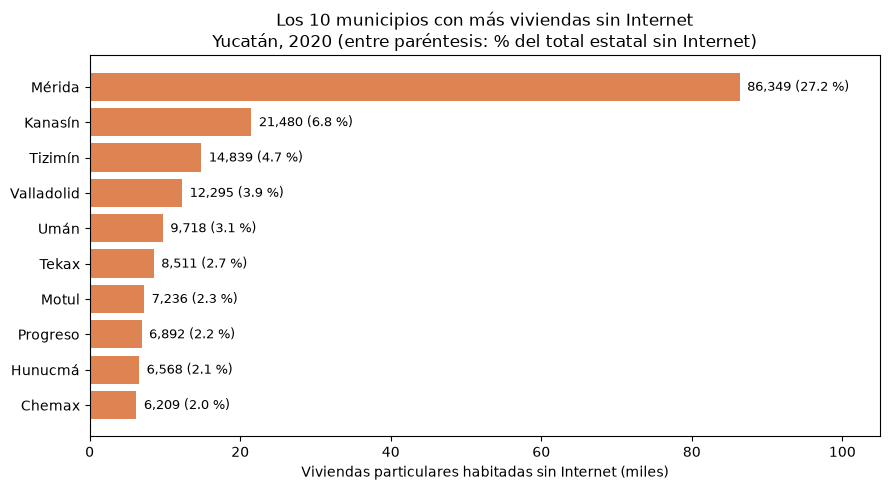

In [31]:
fig, ax = plt.subplots(figsize=(9, 5))
datos = mas_viviendas.sort_values("viv_sin_internet")
ax.barh(datos["NOM_MUN"], datos["viv_sin_internet"] / 1000, color="#DD8452")
for y, (v, p) in enumerate(zip(datos["viv_sin_internet"], datos["part_deficit_pct"])):
    ax.text(v / 1000 + 1, y, f"{v:,.0f} ({p:.1f} %)", va="center", fontsize=9)
ax.set_xlim(0, 105)
ax.set_title("Los 10 municipios con más viviendas sin Internet\nYucatán, 2020 (entre paréntesis: % del total estatal sin Internet)")
ax.set_xlabel("Viviendas particulares habitadas sin Internet (miles)")
plt.tight_layout()
plt.show()

**Respuesta:** **Mérida** encabeza la lista con ≈86 mil viviendas sin Internet (27.2 % del déficit estatal). Le siguen **Kanasín** (≈21 mil), **Tizimín** (≈15 mil), **Valladolid** (≈12 mil) y **Umán** (≈10 mil). Estos diez municipios suman el 56.7 % de las viviendas sin Internet del estado. Son los municipios más poblados. La lista mezcla municipios con proporciones sin acceso relativamente bajas (Mérida 28 %, Progreso 37 %) con otros que tienen proporciones altas (Tekax, Hunucmá y Chemax, ≈74 %).

### Pregunta 4. ¿Coinciden ambos grupos de municipios?

In [32]:
top_proporcion = set(tabla.nlargest(10, "pct_sin_internet")["NOM_MUN"])
top_volumen = set(tabla.nlargest(10, "viv_sin_internet")["NOM_MUN"])

print("Municipios en ambos top 10:", sorted(top_proporcion & top_volumen) or "ninguno")

rangos = tabla.assign(
    rango_proporcion=tabla["pct_sin_internet"].rank(ascending=False, method="min").astype(int),
    rango_volumen=tabla["viv_sin_internet"].rank(ascending=False, method="min").astype(int),
)
# Correlación de Spearman = correlación de Pearson entre los rangos
rho = rangos["rango_proporcion"].corr(rangos["rango_volumen"])
print(f"Correlación de Spearman entre % sin Internet y número de viviendas sin Internet: {rho:.2f}")

Municipios en ambos top 10: ninguno
Correlación de Spearman entre % sin Internet y número de viviendas sin Internet: 0.02


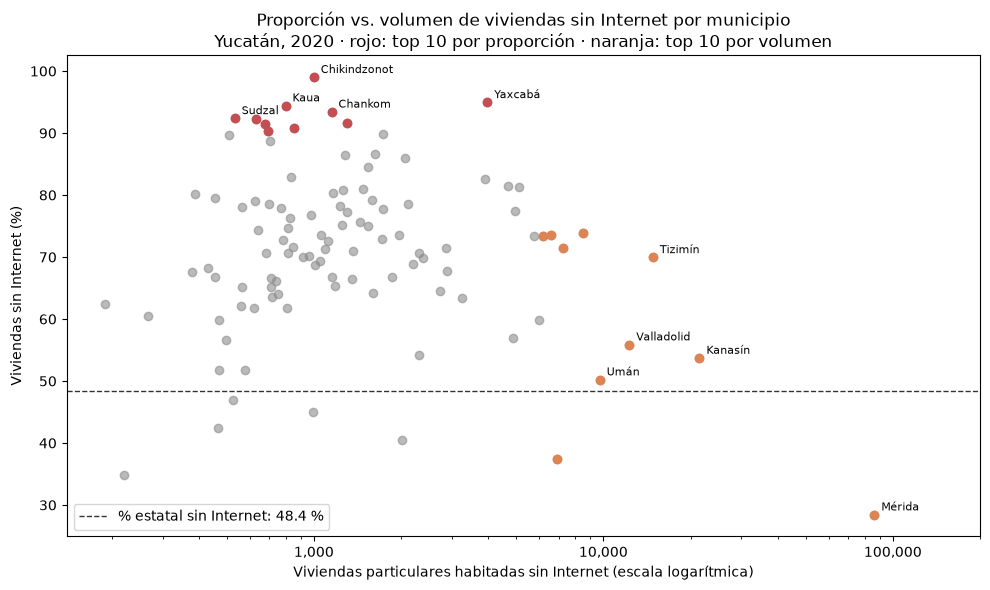

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(tabla["viv_sin_internet"], tabla["pct_sin_internet"], color="#8C8C8C", alpha=0.6)
rojos = tabla[tabla["NOM_MUN"].isin(top_proporcion)]
naranjas = tabla[tabla["NOM_MUN"].isin(top_volumen)]
ax.scatter(rojos["viv_sin_internet"], rojos["pct_sin_internet"], color="#C44E52")
ax.scatter(naranjas["viv_sin_internet"], naranjas["pct_sin_internet"], color="#DD8452")
# Solo se etiquetan los 5 primeros de cada criterio para que los nombres no se encimen
for _, f in pd.concat([rojos.nlargest(5, "pct_sin_internet"), naranjas.nlargest(5, "viv_sin_internet")]).iterrows():
    ax.annotate(f["NOM_MUN"], (f["viv_sin_internet"], f["pct_sin_internet"]), fontsize=8, xytext=(5, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlim(right=200_000)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.axhline(100 - pct_estatal, color="#333333", linestyle="--", linewidth=1, label=f"% estatal sin Internet: {100 - pct_estatal:.1f} %")
ax.set_title("Proporción vs. volumen de viviendas sin Internet por municipio\nYucatán, 2020 · rojo: top 10 por proporción · naranja: top 10 por volumen")
ax.set_xlabel("Viviendas particulares habitadas sin Internet (escala logarítmica)")
ax.set_ylabel("Viviendas sin Internet (%)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

**Respuesta:** **no coinciden: ningún municipio aparece en los dos top 10.** La correlación de Spearman entre ambos criterios es prácticamente **nula (≈0.02)**: saber qué proporción de viviendas no tiene Internet no dice casi nada sobre cuántas viviendas afectadas hay. Los municipios con mayor *proporción* sin acceso son pequeños (entre 577 y 4,184 viviendas). Los que tienen más viviendas afectadas son los más grandes. En la gráfica, los dos grupos quedan en zonas distintas: los rojos arriba a la izquierda y los naranjas a la derecha.

### Pregunta 5. ¿Qué diferencias hay entre el porcentaje de cada municipio y el porcentaje estatal?

In [34]:
tabla["brecha_pp"].describe().round(1)

count    106.0
mean     -22.9
std       13.6
min      -50.6
25%      -30.8
50%      -23.2
75%      -16.3
max       19.9
Name: brecha_pp, dtype: float64

In [35]:
cortes = pd.cut(tabla["brecha_pp"], bins=[-60, -40, -30, -20, -10, 0, 25],
                labels=["más de 40 pp abajo", "30 a 40 pp abajo", "20 a 30 pp abajo",
                        "10 a 20 pp abajo", "0 a 10 pp abajo", "por encima del estado"])
cortes.value_counts().sort_index().rename("municipios").to_frame()

,municipios
brecha_pp,
más de 40 pp abajo,13
30 a 40 pp abajo,17
20 a 30 pp abajo,37
10 a 20 pp abajo,24
0 a 10 pp abajo,8
por encima del estado,7


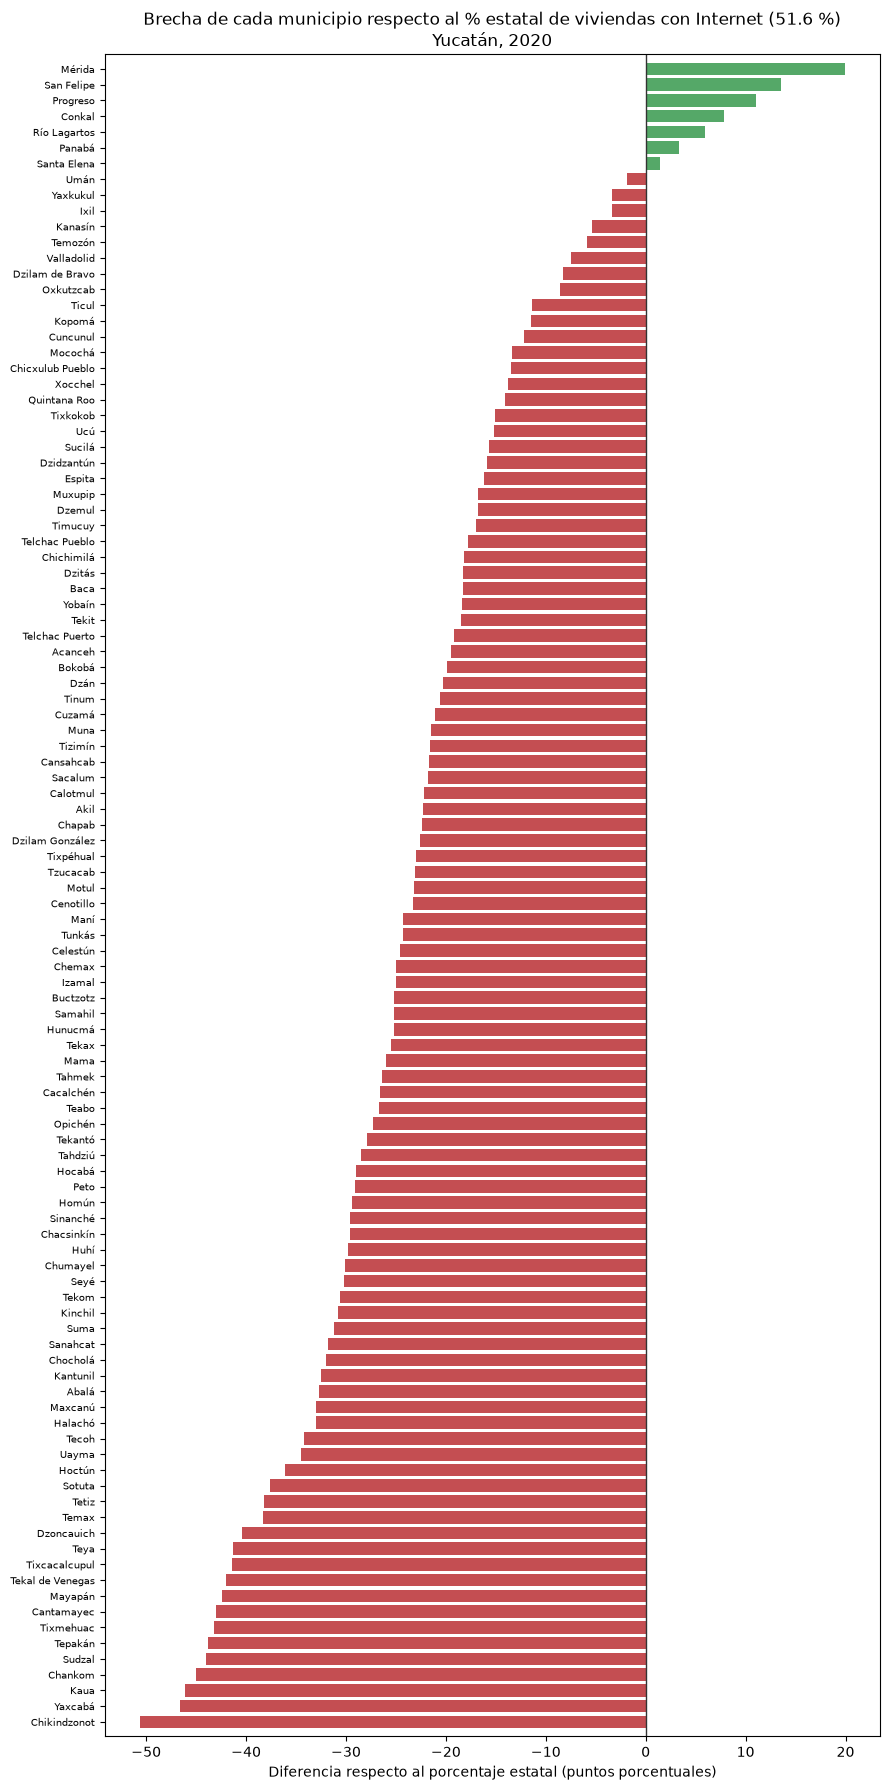

In [36]:
orden = tabla.sort_values("brecha_pp")
fig, ax = plt.subplots(figsize=(9, 18))
colores = ["#55A868" if b > 0 else "#C44E52" for b in orden["brecha_pp"]]
ax.barh(orden["NOM_MUN"], orden["brecha_pp"], color=colores)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title(f"Brecha de cada municipio respecto al % estatal de viviendas con Internet ({pct_estatal:.1f} %)\nYucatán, 2020")
ax.set_xlabel("Diferencia respecto al porcentaje estatal (puntos porcentuales)")
ax.tick_params(axis="y", labelsize=7)
ax.margins(y=0.005)
plt.tight_layout()
plt.show()

**Respuesta:** solo **7 municipios** superan el porcentaje estatal de 51.6 %: Mérida (+19.9 pp), San Felipe (+13.5), Progreso (+11.0), Conkal (+7.8), Río Lagartos (+5.9), Panabá (+3.3) y Santa Elena (+1.5). Los otros **99 municipios** quedan por debajo, 67 de ellos a más de 20 pp. La brecha mediana es de −23.2 pp, y en el extremo Chikindzonot queda **50.6 pp** por debajo. El porcentaje estatal está "arrastrado" hacia arriba por el peso de Mérida, así que no describe la situación de un municipio típico de Yucatán.

### Pregunta 6. ¿Cómo cambia la priorización según el criterio? ¿Qué límites tiene usar datos de 2020?

In [37]:
comparacion = pd.DataFrame({
    "Prioridad por proporción sin acceso": tabla.nlargest(10, "pct_sin_internet")["NOM_MUN"].values,
    "% sin Internet": tabla.nlargest(10, "pct_sin_internet")["pct_sin_internet"].round(1).values,
    "Prioridad por viviendas afectadas": tabla.nlargest(10, "viv_sin_internet")["NOM_MUN"].values,
    "Viviendas sin Internet": tabla.nlargest(10, "viv_sin_internet")["viv_sin_internet"].values,
}, index=range(1, 11))
comparacion

,Prioridad por proporción sin acceso,% sin Internet,Prioridad por viviendas afectadas,Viviendas sin Internet
1,Chikindzonot,99.0,Mérida,86349
2,Yaxcabá,95.0,Kanasín,21480
3,Kaua,94.4,Tizimín,14839
4,Chankom,93.4,Valladolid,12295
5,Sudzal,92.4,Umán,9718
6,Tepakán,92.2,Tekax,8511
7,Tixmehuac,91.6,Motul,7236
8,Cantamayec,91.4,Progreso,6892
9,Mayapán,90.8,Hunucmá,6568
10,Tekal de Venegas,90.4,Chemax,6209


In [38]:
cubre_prop = tabla.nlargest(10, "pct_sin_internet")["viv_sin_internet"].sum()
cubre_vol = tabla.nlargest(10, "viv_sin_internet")["viv_sin_internet"].sum()
print(f"Top 10 por proporción: atiende {cubre_prop:,} viviendas ({cubre_prop / sin_estatal:.1%} del déficit estatal)")
print(f"Top 10 por volumen:    atiende {cubre_vol:,} viviendas ({cubre_vol / sin_estatal:.1%} del déficit estatal)")

Top 10 por proporción: atiende 11,616 viviendas (3.7% del déficit estatal)
Top 10 por volumen:    atiende 180,097 viviendas (56.7% del déficit estatal)


Un criterio combinado puede ayudar a la decisión. Clasificamos los municipios según si están por encima de la **mediana** en ambos criterios:

In [39]:
med_pct = tabla["pct_sin_internet"].median()
med_viv = tabla["viv_sin_internet"].median()

def cuadrante(f):
    alta_prop = f["pct_sin_internet"] > med_pct
    alto_vol = f["viv_sin_internet"] > med_viv
    if alta_prop and alto_vol:
        return "A. Alta proporción y alto volumen"
    if alta_prop:
        return "B. Alta proporción, bajo volumen"
    if alto_vol:
        return "C. Baja proporción, alto volumen"
    return "D. Baja proporción y bajo volumen"

tabla["cuadrante"] = tabla.apply(cuadrante, axis=1)
resumen_cuadrantes = tabla.groupby("cuadrante").agg(
    municipios=("NOM_MUN", "count"),
    viviendas_sin_internet=("viv_sin_internet", "sum"),
)
resumen_cuadrantes["pct_deficit"] = (resumen_cuadrantes["viviendas_sin_internet"] / sin_estatal * 100).round(1)
resumen_cuadrantes

,municipios,viviendas_sin_internet,pct_deficit
cuadrante,,,
A. Alta proporción y alto volumen,29,80178,25.2
"B. Alta proporción, bajo volumen",24,17816,5.6
"C. Baja proporción, alto volumen",24,201117,63.3
D. Baja proporción y bajo volumen,29,18654,5.9


In [40]:
tabla[tabla["cuadrante"].str.startswith("A")].nlargest(10, "viv_sin_internet")[["NOM_MUN", "viv_sin_internet", "pct_sin_internet"]].round(1)

,NOM_MUN,viv_sin_internet,pct_sin_internet
78,Tekax,8511,73.8
37,Hunucmá,6568,73.6
18,Chemax,6209,73.4
39,Izamal,5765,73.4
47,Maxcanú,5125,81.4
57,Peto,4954,77.5
32,Halachó,4672,81.4
103,Yaxcabá,3973,95.0
75,Tecoh,3895,82.6
66,Seyé,2117,78.6


**Respuesta: la priorización cambia por completo.**

- **Por proporción** se priorizan municipios pequeños del oriente y el sur (Chikindzonot, Yaxcabá, Kaua, Chankom…). Ahí la falta de acceso es casi total, pero en conjunto solo representan un porcentaje pequeño del déficit estatal. Es un criterio de **equidad**: atender a las poblaciones más rezagadas.
- **Por volumen** se priorizan Mérida, Kanasín, Tizimín, Valladolid… Con diez municipios se cubre más de la mitad de las viviendas sin acceso del estado. Es un criterio de **alcance o eficiencia**: más hogares por acción.
- **En números:** los 10 municipios priorizados por proporción suman 11,616 viviendas sin Internet (3.7 % del déficit estatal). Los 10 priorizados por volumen suman 180,097 (56.7 %).
- El cuadrante **A** (por encima de la mediana en ambos criterios) reúne 29 municipios con el 25.2 % del déficit. Entre ellos están Tekax, Hunucmá, Chemax, Izamal, Maxcanú y Peto. Combina ambos criterios y es un buen punto de partida.

**Límites de usar datos de 2020 para una decisión actual:**
1. **Antigüedad:** la fecha de referencia es marzo de 2020, al inicio de la pandemia. La educación y el trabajo a distancia aceleraron la contratación de Internet, así que los niveles actuales probablemente son mayores y la brecha pudo cambiar de forma distinta en cada municipio.
2. **Cambios en la oferta:** desde 2020 se han ampliado redes y programas públicos de conectividad que no se reflejan en el censo.
3. **Crecimiento urbano:** la zona metropolitana de Mérida (Kanasín, Umán, Conkal) ha crecido mucho, lo que modifica el número de viviendas afectadas.
4. **Lo que el censo no mide:** la calidad o velocidad de la conexión, el costo, el uso real por persona, el acceso por datos móviles fuera del hogar ni las habilidades digitales.
5. **Sin "no especificado" separado:** el conteo sin Internet es un límite superior.

Para una decisión actual habría que actualizar con la ENDUTIH más reciente (solo a nivel estatal), con datos de cobertura de redes del IFT/CRT o con un levantamiento propio en los municipios priorizados.

## 7. Indicadores, hallazgos, recomendación y limitaciones

### Indicadores

In [41]:
indicadores = pd.DataFrame([
    {"Indicador": "% de viviendas con Internet",
     "Definición": "Proporción de viviendas particulares habitadas con características que disponen de Internet",
     "Fórmula": "VPH_INTER / VIVPARH_CV × 100", "Unidad": "%",
     "Resultado de referencia": f"{pct_estatal:.1f} %"},
    {"Indicador": "Viviendas sin Internet",
     "Definición": "Viviendas particulares habitadas con características que no reportan Internet",
     "Fórmula": "VIVPARH_CV − VPH_INTER", "Unidad": "viviendas",
     "Resultado de referencia": f"{sin_estatal:,}"},
    {"Indicador": "Brecha respecto al estado",
     "Definición": "Diferencia entre el % municipal y el % estatal con Internet",
     "Fórmula": "% municipal − % estatal", "Unidad": "pp",
     "Resultado de referencia": f"mediana municipal {tabla['brecha_pp'].median():.1f} pp"},
    {"Indicador": "Participación en el déficit estatal",
     "Definición": "Peso de cada municipio en el total de viviendas sin Internet del estado",
     "Fórmula": "viviendas sin Internet mun. / viviendas sin Internet estado × 100", "Unidad": "%",
     "Resultado de referencia": f"Mérida {tabla.loc[tabla['NOM_MUN'] == 'Mérida', 'part_deficit_pct'].iloc[0]:.1f} %"},
])
indicadores["Periodo de referencia"] = "Censo 2020 (15 de marzo de 2020)"
indicadores

,Indicador,Definición,Fórmula,Unidad,Resultado de referencia,Periodo de referencia
0,% de viviendas con Internet,Proporción de viviendas particulares habitadas con características que disponen de Internet,VPH_INTER / VIVPARH_CV × 100,%,51.6 %,Censo 2020 (15 de marzo de 2020)
1,Viviendas sin Internet,Viviendas particulares habitadas con características que no reportan Internet,VIVPARH_CV − VPH_INTER,viviendas,"317,765",Censo 2020 (15 de marzo de 2020)
2,Brecha respecto al estado,Diferencia entre el % municipal y el % estatal con Internet,% municipal − % estatal,pp,mediana municipal -23.2 pp,Censo 2020 (15 de marzo de 2020)
3,Participación en el déficit estatal,Peso de cada municipio en el total de viviendas sin Internet del estado,viviendas sin Internet mun. / viviendas sin Internet estado × 100,%,Mérida 27.2 %,Censo 2020 (15 de marzo de 2020)


### Hallazgos sustentados

1. **La brecha es amplia y generalizada.** El 51.6 % de las viviendas de Yucatán tenía Internet en 2020, pero solo 7 de 106 municipios superan ese nivel. La mitad de los municipios no llega al 28.4 %. El dato estatal oculta la situación de la mayoría de los municipios: el promedio simple municipal es de 28.7 %.
2. **Proporción y volumen señalan municipios distintos.** Ningún municipio está a la vez en el top 10 por proporción y en el top 10 por volumen, y la correlación entre ambos criterios es prácticamente nula (ρ ≈ 0.02). Chikindzonot tiene al 99 % de sus viviendas sin Internet (1,000 viviendas). Mérida tiene al 28 % sin acceso, pero son ≈86 mil viviendas, el 27 % del déficit estatal.
3. **La brecha no se explica por falta de teléfono ni solo por la ruralidad.** En los diez municipios con menor conectividad, entre el 50 % y el 82 % de las viviendas tiene celular, pero menos del 10 % tiene Internet. La disponibilidad de teléfono celular y la disponibilidad de Internet en la vivienda son indicadores distintos. Estos agregados no permiten identificar la situación de cada hogar ni la causa de la falta de acceso. La ruralidad medida por el tamaño de localidad tiene una asociación débil (ρ ≈ −0.13), Este resultado no identifica causas. Para evaluar el papel de infraestructura o ingreso se necesitan otras fuentes.

### Recomendación

Una estrategia en **dos frentes**, según el objetivo:
- **Diagnóstico de cobertura en los municipios más rezagados** (Chikindzonot, Yaxcabá, Kaua, Chankom, Sudzal, Tepakán, Tixmehuac…): verificar cobertura, calidad y costos. Si se confirma falta de infraestructura, valorar conectividad pública o comunitaria.
- **Diagnóstico de barreras en los municipios de mayor volumen** (Mérida, Kanasín, Tizimín, Valladolid, Umán): investigar cobertura, costos, habilidades y motivos de falta de acceso antes de elegir apoyos a la contratación. El ITER no demuestra cuál de estas barreras predomina.
- Empezar por el **cuadrante A** (por ejemplo, Tekax, Hunucmá, Chemax, Izamal, Maxcanú y Peto), que combina alta proporción y alto volumen.

Antes de asignar recursos, conviene **actualizar el diagnóstico** con datos más recientes (ver pregunta 6).

### Limitaciones del análisis
- Datos con fecha de referencia de marzo de 2020; no reflejan el efecto de la pandemia ni las inversiones posteriores.
- Se mide la disponibilidad de Internet en la vivienda, no su calidad, su costo ni su uso individual.
- El conteo sin Internet incluye a las viviendas que no especificaron (límite superior).
- El análisis municipal oculta las diferencias entre localidades de un mismo municipio. El nivel de localidad tiene datos reservados (`*`) en las localidades más pequeñas.
- Las asociaciones con ruralidad y celular son descriptivas; no establecen causas.

**Alcance de la priorización:** 3.7 % y 56.7 % son participaciones del déficit observado en los municipios seleccionados. No son pronósticos de cuánto resolvería un programa ni estimaciones de costo o de impacto.
